<a href="https://colab.research.google.com/github/tanvir0192415-crypto/uncertainty-propagation-clinical-reports/blob/main/Uncertainty_aware_information_extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install scikit-survival lifelines

import numpy as np, pandas as pd
from sksurv.datasets import load_gbsg2

X, y = load_gbsg2()
df = X.copy()
df["event"] = y["cens"]
df["time"] = y["time"]

print(df.shape)
print(df.head())
print(df.dtypes)
print(df["tgrade"].value_counts())
print("event rate:", df["event"].mean())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.4/142.4 kB 4.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 53.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 83.4 MB/s eta 0:00:00
(686, 10)
    age  estrec horTh menostat  pnodes  progrec tgrade  tsize  event    time
0  70.0    66.0    no     Post     3.0     48.0     II   21.0   True  1814.0
1  56.0    77.0   yes     Post     7.0     61.0     II   12.0   True  2018.0
2  58.0   271.0   yes     Post     9.0     52.0     II   35.0   True   712.0
3  59.0    29.0   yes     Post     4.0     60.0     II   17.0   True  1807.0
4  73.0    65.0    no     Post     1.0     26.0     II   35.0   True   772.0
age          float64
estrec       fl

In [2]:
rng = np.random.default_rng(42)

phr = {
    "I":   ["well differentiated", "low grade", "grade 1", "Nottingham score 3-5", "prominent tubule formation"],
    "II":  ["moderately differentiated", "intermediate grade", "grade 2", "Nottingham score 6-7", "moderate nuclear pleomorphism"],
    "III": ["poorly differentiated", "high grade", "grade 3", "Nottingham score 8-9", "marked nuclear pleomorphism"],
}
neighbour = {"I": ["II"], "II": ["I", "III"], "III": ["II"]}
hedges = ["", "", "", "features suggestive of ", "consistent with ", "focally "]

def make_report(g, size):
    parts = []
    for _ in range(2):
        gg = g if rng.random() < 0.70 else str(rng.choice(neighbour[g]))
        parts.append(str(rng.choice(hedges)) + str(rng.choice(phr[gg])))
    return f"Invasive ductal carcinoma, {int(size)} mm. Histology: {'; '.join(parts)}."

df["grade"] = df["tgrade"].astype(str)
df["report"] = [make_report(g, s) for g, s in zip(df["grade"], df["tsize"])]

for i in range(6):
    print(df.loc[i, "grade"], "|", df.loc[i, "report"])

II | Invasive ductal carcinoma, 21 mm. Histology: grade 3; focally intermediate grade.
II | Invasive ductal carcinoma, 12 mm. Histology: consistent with Nottingham score 3-5; marked nuclear pleomorphism.
II | Invasive ductal carcinoma, 35 mm. Histology: moderately differentiated; focally grade 2.
II | Invasive ductal carcinoma, 17 mm. Histology: consistent with grade 2; moderate nuclear pleomorphism.
II | Invasive ductal carcinoma, 35 mm. Histology: Nottingham score 3-5; poorly differentiated.
III | Invasive ductal carcinoma, 57 mm. Histology: focally Nottingham score 6-7; consistent with high grade.


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix

classes = ["I", "II", "III"]
pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

proba = cross_val_predict(pipe, df["report"], df["grade"], cv=skf, method="predict_proba")
pred = np.array(classes)[proba.argmax(axis=1)]

df[["p_I", "p_II", "p_III"]] = proba

print("accuracy:", round(accuracy_score(df["grade"], pred), 3))
print(confusion_matrix(df["grade"], pred, labels=classes))
print("mean max-probability (confidence):", round(proba.max(axis=1).mean(), 3))
print(df[["grade", "p_I", "p_II", "p_III"]].head().round(2))

accuracy: 0.692
[[ 10  70   1]
 [  3 410  31]
 [  0 106  55]]
mean max-probability (confidence): 0.69
  grade   p_I  p_II  p_III
0    II  0.04  0.92   0.04
1    II  0.09  0.62   0.29
2    II  0.09  0.70   0.21
3    II  0.08  0.74   0.18
4    II  0.07  0.39   0.54


ECE: 0.0354


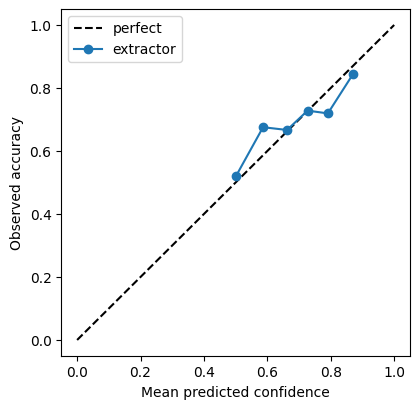

[[0.502 0.522]
 [0.586 0.675]
 [0.662 0.667]
 [0.727 0.728]
 [0.791 0.719]
 [0.87  0.843]]


In [4]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

conf = proba.max(axis=1)
correct = (pred == df["grade"].values).astype(int)

frac_pos, mean_conf = calibration_curve(correct, conf, n_bins=6, strategy="quantile")

# Expected Calibration Error (ECE)
bins = np.quantile(conf, np.linspace(0, 1, 7))
ece = 0.0
for lo, hi in zip(bins[:-1], bins[1:]):
    m = (conf >= lo) & (conf <= hi)
    if m.sum() > 0:
        ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
print("ECE:", round(ece, 4))

plt.figure(figsize=(4.5, 4.5))
plt.plot([0, 1], [0, 1], "k--", label="perfect")
plt.plot(mean_conf, frac_pos, "o-", label="extractor")
plt.xlabel("Mean predicted confidence")
plt.ylabel("Observed accuracy")
plt.legend()
plt.show()
print(np.c_[mean_conf, frac_pos].round(3))

In [5]:
from lifelines import CoxPHFitter

covs = ["age", "estrec", "progrec", "pnodes", "tsize"]
base = df[covs + ["time"]].copy()
base["event"] = df["event"].astype(int)
base["horTh_yes"] = (df["horTh"].astype(str) == "yes").astype(int)

def fit_cox(g):
    g = pd.Series(np.asarray(g), index=df.index)
    d = base.copy()
    d["grade_II"] = (g == "II").astype(int)
    d["grade_III"] = (g == "III").astype(int)
    return CoxPHFitter().fit(d, duration_col="time", event_col="event")

m_true = fit_cox(df["grade"].values)   # oracle: uses the true grade
m_plug = fit_cox(pred)                 # naive: uses the extractor's hard label

for name, m in [("TRUE grade", m_true), ("PLUG-IN label", m_plug)]:
    print(name)
    print(m.summary.loc[["grade_II", "grade_III"], ["coef", "se(coef)", "coef lower 95%", "coef upper 95%"]].round(3))
    print()

TRUE grade
            coef  se(coef)  coef lower 95%  coef upper 95%
covariate                                                 
grade_II   0.647     0.249           0.159           1.135
grade_III  0.790     0.268           0.264           1.315

PLUG-IN label
            coef  se(coef)  coef lower 95%  coef upper 95%
covariate                                                 
grade_II   0.237     0.508          -0.758           1.232
grade_III  0.243     0.529          -0.795           1.280



In [6]:
rng = np.random.default_rng(1)
M = 100
cum = proba.cumsum(axis=1)
coefs, ses = [], []

for _ in range(M):
    u = rng.random(len(df))[:, None]
    idx = np.minimum((u > cum).sum(axis=1), 2)
    g = np.array(classes)[idx]
    m = fit_cox(g)
    coefs.append(m.params_[["grade_II", "grade_III"]].values)
    ses.append(m.standard_errors_[["grade_II", "grade_III"]].values)

coefs, ses = np.array(coefs), np.array(ses)
Qbar = coefs.mean(axis=0)                       # pooled estimate
W = (ses**2).mean(axis=0)                       # within-imputation variance
B = coefs.var(axis=0, ddof=1)                   # between-imputation variance
T = W + (1 + 1/M) * B                           # total variance (Rubin)
se = np.sqrt(T)

out = pd.DataFrame({"coef": Qbar, "se": se,
                    "lower95": Qbar - 1.96*se, "upper95": Qbar + 1.96*se},
                   index=["grade_II", "grade_III"]).round(3)
print(out)

            coef     se  lower95  upper95
grade_II   0.009  0.255    -0.49    0.508
grade_III  0.040  0.291    -0.53    0.609


In [9]:
import torch
from scipy.optimize import minimize

t = torch.tensor(df["time"].values / 365.25, dtype=torch.float64)   # years
d = torch.tensor(df["event"].astype(int).values, dtype=torch.float64)
Xc = base[covs + ["horTh_yes"]].copy()
Xc[covs] = (Xc[covs] - Xc[covs].mean()) / Xc[covs].std()
X = torch.tensor(Xc.values, dtype=torch.float64)
p = X.shape[1]
logt = torch.log(t)

def nll(theta, W):
    b0, logrho = theta[0], theta[1]
    beta = theta[2:2+p]
    gam = torch.cat([torch.zeros(1, dtype=torch.float64), theta[2+p:4+p]])  # grade I = reference
    rho = torch.exp(logrho)
    eta_g = (b0 + X @ beta)[:, None] + gam[None, :]                          # n x 3
    ll = d[:, None] * (logrho + (rho - 1) * logt[:, None] + eta_g) - torch.exp(rho * logt[:, None] + eta_g)
    logW = torch.log(W.clamp_min(1e-12))
    return -torch.logsumexp(logW + ll, dim=1).sum() + 0.5 * (gam[1:] ** 2).sum() / 1.5 ** 2

def fit(W):
    W = torch.tensor(W, dtype=torch.float64)
    th0 = np.zeros(4 + p); th0[0] = -1.0
    f = lambda th: nll(torch.tensor(th, dtype=torch.float64), W).item()
    def g(th):
        x = torch.tensor(th, dtype=torch.float64, requires_grad=True)
        nll(x, W).backward()
        return x.grad.numpy()
    res = minimize(f, th0, jac=g, method="BFGS")
    H = torch.autograd.functional.hessian(lambda x: nll(x, W), torch.tensor(res.x, dtype=torch.float64))
    se = np.sqrt(np.diag(np.linalg.inv(H.numpy())))
    return res, se

gmap = {"I": 0, "II": 1, "III": 2}
settings = [("TRUE grade (oracle)", np.eye(3)[df["grade"].map(gmap).values]),
            ("PLUG-IN label",       np.eye(3)[proba.argmax(1)]),
            ("MARGINAL (probabilities)", proba)]

rows = []
for name, W in settings:
    res, se = fit(W)
    for j, gname in enumerate(["grade_II", "grade_III"]):
        c, s = res.x[2+p+j], se[2+p+j]
        rows.append([name, gname, round(c, 3), round(s, 3), round(c-1.96*s, 3), round(c+1.96*s, 3), res.success])
print(pd.DataFrame(rows, columns=["method", "term", "coef", "se", "lower95", "upper95", "converged"]).to_string(index=False))

                  method      term  coef    se  lower95  upper95  converged
     TRUE grade (oracle)  grade_II 0.630 0.239    0.161    1.099       True
     TRUE grade (oracle) grade_III 0.778 0.258    0.271    1.284       True
           PLUG-IN label  grade_II 0.207 0.450   -0.676    1.090       True
           PLUG-IN label grade_III 0.203 0.471   -0.719    1.126       True
MARGINAL (probabilities)  grade_II 1.771 0.716    0.367    3.175       True
MARGINAL (probabilities) grade_III 1.606 0.695    0.244    2.968       True


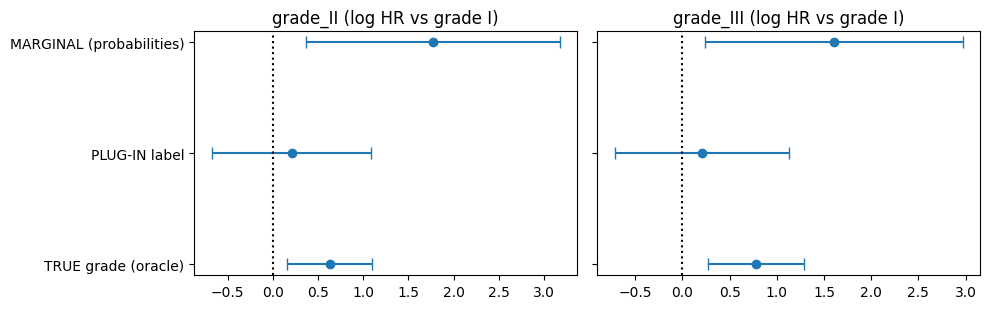

In [10]:
res_df = pd.DataFrame(rows, columns=["method","term","coef","se","lower95","upper95","converged"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, term in zip(axes, ["grade_II", "grade_III"]):
    s = res_df[res_df.term == term].reset_index(drop=True)
    ax.errorbar(s.coef, range(len(s)), xerr=[s.coef - s.lower95, s.upper95 - s.coef], fmt="o", capsize=4)
    ax.axvline(0, color="k", ls=":")
    ax.set_yticks(range(len(s)))
    ax.set_yticklabels(s.method)
    ax.invert_yaxis()
    ax.set_title(term + " (log HR vs grade I)")
plt.tight_layout()
plt.savefig("forest_plot.png", dpi=200)
plt.show()
res_df.to_csv("results_weibull.csv", index=False)